# 03 · How much does a contract's ceiling grow? Two-part Gamma model and quantile regression

**Outcome:** growth ratio = final ceiling ÷ ceiling at signing.

Notebook 01 showed three regimes: 53% unchanged (ratio exactly 1), 20% shrank, 27% grew. That rules out a single
Gamma or log-normal model, so this notebook splits the question:

1. **Hurdle (logistic):** does the award grow at all?
2. **Severity (Gamma GLM, log link):** for awards that grew, by how much? Outcome = excess growth (ratio − 1) > 0.
   The Gamma model is checked against a log-normal alternative and its variance function is tested directly.
3. **Quantile regression:** what drives the *tails* of log growth (big overruns, big descopes) as opposed to the
   typical award? The mean can hide effects that only show up at the 90th-95th percentile.

Collinearity (VIF) and heteroscedasticity (Breusch-Pagan) checks are included because they decide which of these
models' standard errors can be trusted.

In [1]:
import sys; sys.path.append("..")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.features import RHS, load_awards, model_frame

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
df = model_frame(load_awards())

# Ratios above the 99.5th percentile (> ~20x) are mostly recording errors in the initial ceiling; cap them for
# the mean models. Quantile regression is robust to them, so it uses the uncapped values.
cap = df["growth_ratio"].quantile(0.995)
df["growth_capped"] = df["growth_ratio"].clip(upper=cap)
df["excess"] = df["growth_capped"] - 1
print(f"cap at {cap:.1f}x; {(df['growth_ratio'] > cap).sum()} awards affected")

cap at 20.3x; 304 awards affected


## 0. Collinearity check

Variance inflation factors for the shared design matrix. VIF > 5-10 means a coefficient's standard error is
badly inflated by overlap with other predictors.

In [2]:
import patsy
X = patsy.dmatrix(RHS, df, return_type="dataframe")
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
vif.drop("Intercept").sort_values(ascending=False).head(12).round(2).to_frame("VIF")

,VIF
solicitation_missing,4.93
log_solicitation_days,4.12
single_offer,3.56
C(base_fiscal_year)[T.2023],3.03
C(base_fiscal_year)[T.2022],2.96
C(base_fiscal_year)[T.2021],2.79
C(base_fiscal_year)[T.2018],2.77
C(base_fiscal_year)[T.2020],2.74
C(base_fiscal_year)[T.2019],2.70
C(base_fiscal_year)[T.2016],2.58


The fiscal-year dummies and `log_planned_years` sit in the mild range. The pair to watch is
`september` and `final_two_weeks`: the second is a subset of the first, so each is interpreted *holding the other
fixed*. "September but not the final two weeks" vs "the final two weeks" is the contrast we want, so both stay.

## 1. Hurdle: does the ceiling grow at all?

In [3]:
hurdle = smf.logit("any_growth ~ " + RHS, data=df).fit(disp=0)
def odds_table(res, keep):
    ci = res.conf_int()
    t = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                      "p": res.pvalues})
    return t[t.index.str.contains(keep)].round(3)
print(f"pseudo R² = {hurdle.prsquared:.3f}")
odds_table(hurdle, "pricing|competition|single_offer|september|final_two|log_ceiling|log_planned|psc_group")

pseudo R² = 0.124


,odds_ratio,ci_low,ci_high,p
"C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]",0.912,0.845,0.985,0.018
"C(pricing, Treatment('firm_fixed'))[T.fixed_other]",1.026,0.788,1.336,0.849
"C(pricing, Treatment('firm_fixed'))[T.time_materials]",1.299,1.213,1.391,0.000
"C(competition, Treatment('full_open'))[T.not_competed]",1.093,1.023,1.168,0.008
"C(competition, Treatment('full_open'))[T.other]",2.320,0.582,9.250,0.233
"C(competition, Treatment('full_open'))[T.set_aside]",0.942,0.883,1.004,0.067
"C(competition, Treatment('full_open'))[T.simplified]",1.298,1.200,1.404,0.000
"C(psc_group, Treatment('products'))[T.architect_engineering]",5.071,4.570,5.627,0.000
"C(psc_group, Treatment('products'))[T.construction]",3.231,2.895,3.606,0.000
"C(psc_group, Treatment('products'))[T.education_training]",1.500,1.305,1.723,0.000


## 2. Severity: Gamma GLM on excess growth, for awards that grew

A Gamma GLM with log link models E[excess] = exp(Xβ) with Var = φ·μ². Before trusting it, check the variance
assumption directly with a **Park test**: regress log(squared raw residual) on log(fitted mean). A slope near 2
supports Gamma; near 1 would point to Poisson-like (quasi-Poisson) variance, near 3 to inverse Gaussian.

In [4]:
grew = df[df["any_growth"] == 1].copy()
gamma = smf.glm("excess ~ " + RHS, data=grew, family=sm.families.Gamma(sm.families.links.Log())).fit(cov_type="HC0")
park = sm.OLS(np.log((grew["excess"] - gamma.fittedvalues) ** 2), sm.add_constant(np.log(gamma.fittedvalues))).fit()
print(f"n = {len(grew):,}; Gamma dispersion φ = {gamma.scale:.2f}")
print(f"Park test slope = {park.params.iloc[1]:.2f} (95% CI {park.conf_int().iloc[1, 0]:.2f}-{park.conf_int().iloc[1, 1]:.2f})")

n = 16,512; Gamma dispersion φ = 4.12
Park test slope = 2.09 (95% CI 2.06-2.13)


**Gamma vs log-normal.** Both assume the standard deviation is proportional to the mean. They differ in tail
shape. Compare them on the same scale: the log-normal log-likelihood needs the Jacobian term −Σlog(y) to be
comparable with the Gamma likelihood on y.

AIC  Gamma = 41,566   log-normal = 33,960


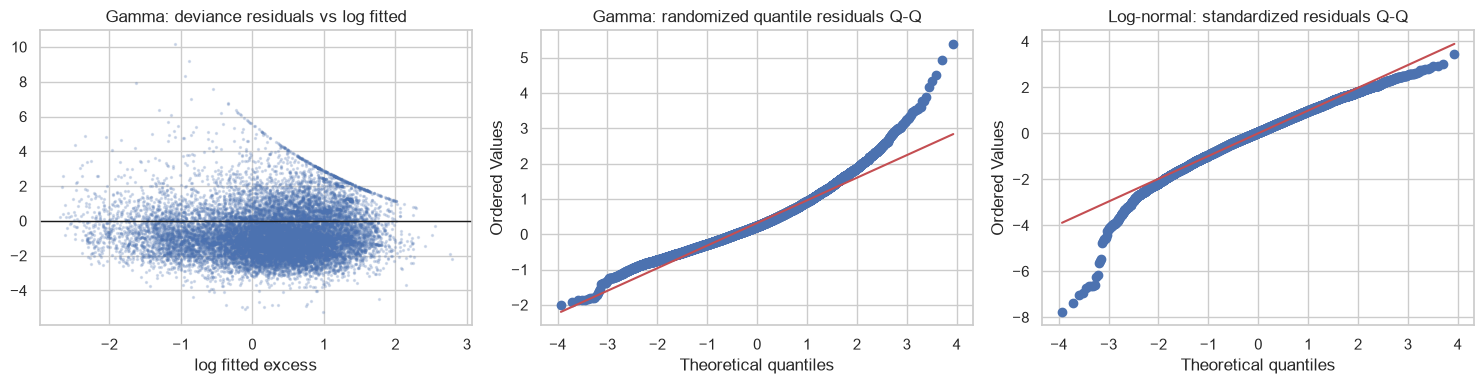

In [5]:
lognorm = smf.ols("np.log(excess) ~ " + RHS, data=grew).fit()
ll_lognorm = lognorm.llf - np.log(grew["excess"]).sum()
k_ln = lognorm.df_model + 2
k_g = gamma.df_model + 2
print(f"AIC  Gamma = {gamma.aic:,.0f}   log-normal = {2 * k_ln - 2 * ll_lognorm:,.0f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
resid_dev = gamma.resid_deviance
ax[0].scatter(np.log(gamma.fittedvalues), resid_dev, s=2, alpha=0.2)
ax[0].axhline(0, color="k", lw=1)
ax[0].set(title="Gamma: deviance residuals vs log fitted", xlabel="log fitted excess")
# Quantile residuals are ~N(0,1) under a correct model, so they can be read off a standard Q-Q plot.
shape = 1 / gamma.scale
u = stats.gamma.cdf(grew["excess"], a=shape, scale=gamma.fittedvalues / shape)
qres = stats.norm.ppf(np.clip(u, 1e-9, 1 - 1e-9))
stats.probplot(qres, dist="norm", plot=ax[1]); ax[1].set_title("Gamma: randomized quantile residuals Q-Q")
stats.probplot(lognorm.resid / np.sqrt(lognorm.scale), dist="norm", plot=ax[2])
ax[2].set_title("Log-normal: standardized residuals Q-Q")
plt.tight_layout(); plt.savefig(FIG + "03_severity_diagnostics.png", dpi=120); plt.show()

The two checks disagree, and the disagreement is informative:
- The **Park slope ≈ 2** says the variance does grow with the square of the mean, as both Gamma and log-normal assume.
- **AIC prefers the log-normal by a wide margin**, and the Gamma quantile residuals bend away from the line in
  the tails. Excess growth spans several orders of magnitude (from +0.1% to +1,900%), and a Gamma with a single
  shape parameter cannot cover that range.

So the log-normal is the better *distributional* model. The Gamma GLM is still useful as a **quasi-likelihood**
model for the mean: with a log link, its coefficients are consistent for E[excess | X] as long as the mean is
specified correctly, even when the Gamma distribution is wrong. That is why it was fitted with sandwich (HC0)
standard errors above. The log-normal needs a retransformation (smearing) correction to say anything about the
mean in dollars. The Gamma gives it directly.

In [6]:
def ratio_table(res, keep):
    ci = res.conf_int()
    t = pd.DataFrame({"multiplier": np.exp(res.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                      "p": res.pvalues})
    return t[t.index.str.contains(keep)].round(3)
ratio_table(gamma, "pricing|competition|single_offer|september|final_two|log_ceiling|log_planned")

,multiplier,ci_low,ci_high,p
"C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]",0.946,0.864,1.036,0.228
"C(pricing, Treatment('firm_fixed'))[T.fixed_other]",0.829,0.607,1.132,0.238
"C(pricing, Treatment('firm_fixed'))[T.time_materials]",1.124,1.015,1.245,0.025
"C(competition, Treatment('full_open'))[T.not_competed]",1.180,1.057,1.318,0.003
"C(competition, Treatment('full_open'))[T.other]",0.467,0.192,1.139,0.094
"C(competition, Treatment('full_open'))[T.set_aside]",0.883,0.795,0.982,0.021
"C(competition, Treatment('full_open'))[T.simplified]",0.764,0.671,0.870,0.000
log_ceiling,0.801,0.777,0.826,0.000
log_planned_years,1.085,1.061,1.111,0.000
single_offer,1.118,0.989,1.264,0.073


## 3. Putting the parts together

Expected excess growth = P(grow) × E[excess | grew]. The table shows this for a typical award under each pricing
type, holding all other features at their observed values (average predictive comparison).

In [7]:
rows = []
for p in ["firm_fixed", "time_materials", "cost_reimbursement"]:
    scen = df.assign(pricing=p)
    p_grow = hurdle.predict(scen)
    sev = gamma.predict(scen)
    rows.append({"pricing": p, "P(grow)": p_grow.mean(), "E[excess | grew]": sev.mean(),
                 "expected excess": (p_grow * sev).mean()})
pd.DataFrame(rows).set_index("pricing").round(3)

,P(grow),E[excess | grew],expected excess
pricing,,,
firm_fixed,0.269,1.585,0.449
time_materials,0.315,1.782,0.592
cost_reimbursement,0.253,1.499,0.401


## 4. Heteroscedasticity check on a plain OLS of log growth

A plain OLS of log growth on all awards is what most analyses would fit first. Breusch-Pagan tests whether its
residual variance depends on the predictors. If it does, OLS standard errors are wrong and the mean misses part
of the story. That motivates the quantile regression below.

In [8]:
ols = smf.ols("log_growth ~ " + RHS, data=df.assign(log_growth=np.log(df["growth_capped"]))).fit()
bp_lm, bp_p, _, _ = het_breuschpagan(ols.resid, ols.model.exog)
print(f"Breusch-Pagan LM = {bp_lm:,.0f}, p = {bp_p:.2g}")
print("Residual SD by pricing type:")
print(ols.resid.groupby(df["pricing"]).std().round(3))

Breusch-Pagan LM = 762, p = 1.1e-128
Residual SD by pricing type:
pricing
cost_reimbursement    0.799
firm_fixed            0.918
fixed_other           0.543
time_materials        0.826
dtype: float64


## 5. Quantile regression: drivers of the tails

Fit linear quantile regression of (uncapped) log growth at τ = 0.10, 0.25, 0.75, 0.90, 0.95. The median is
skipped because over half the awards sit exactly at 0 (ratio 1), which makes the median degenerate. The lower
quantiles describe descoping, the upper ones overruns.

A compact covariate set keeps the fits fast and the plots readable.

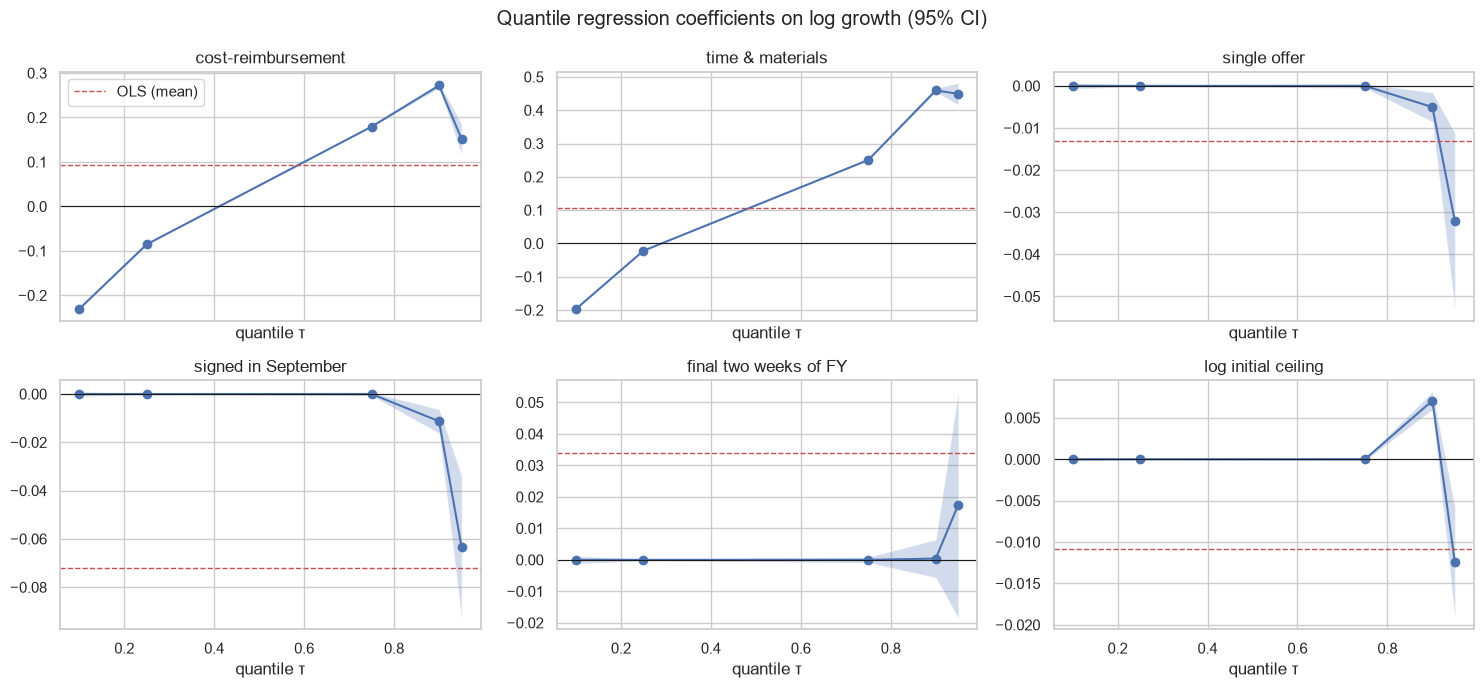

In [9]:
q_rhs = ("log_ceiling + log_planned_years + C(pricing, Treatment('firm_fixed'))"
         " + C(competition, Treatment('full_open')) + single_offer + small_business"
         " + C(psc_group, Treatment('products')) + september + final_two_weeks + C(base_fiscal_year)")
taus = [0.10, 0.25, 0.75, 0.90, 0.95]
qfits = {t: smf.quantreg("log_growth ~ " + q_rhs, df).fit(q=t, max_iter=5000) for t in taus}
ols_q = smf.ols("log_growth ~ " + q_rhs, df).fit()

terms = {
    "C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]": "cost-reimbursement",
    "C(pricing, Treatment('firm_fixed'))[T.time_materials]": "time & materials",
    "single_offer": "single offer",
    "september": "signed in September",
    "final_two_weeks": "final two weeks of FY",
    "log_ceiling": "log initial ceiling",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (term, label) in zip(axes.flat, terms.items()):
    est = [qfits[t].params[term] for t in taus]
    lo = [qfits[t].conf_int().loc[term, 0] for t in taus]
    hi = [qfits[t].conf_int().loc[term, 1] for t in taus]
    ax.fill_between(taus, lo, hi, alpha=0.25)
    ax.plot(taus, est, marker="o")
    ax.axhline(ols_q.params[term], color="r", ls="--", lw=1, label="OLS (mean)")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(label); ax.set_xlabel("quantile τ")
axes.flat[0].legend()
plt.suptitle("Quantile regression coefficients on log growth (95% CI)")
plt.tight_layout(); plt.savefig(FIG + "03_quantile_coefficients.png", dpi=120); plt.show()

In [10]:
qtab = pd.DataFrame({f"τ={t}": [qfits[t].params[k] for k in terms] for t in taus}, index=terms.values())
qtab["OLS"] = [ols_q.params[k] for k in terms]
np.exp(qtab).round(3)

,τ=0.1,τ=0.25,τ=0.75,τ=0.9,τ=0.95,OLS
cost-reimbursement,0.794,0.918,1.196,1.313,1.164,1.097
time & materials,0.821,0.978,1.285,1.583,1.567,1.111
single offer,1.000,1.000,1.000,0.995,0.968,0.987
signed in September,1.000,1.000,1.000,0.989,0.939,0.930
final two weeks of FY,1.000,1.000,1.000,1.000,1.018,1.034
log initial ceiling,1.000,1.000,1.000,1.007,0.988,0.989


The table is on the multiplicative scale (exp of the coefficient). At τ = 0.95 a value of 1.5 means that, for
awards at the 95th percentile of growth, this feature goes with a 50% larger growth ratio. Effects that are near 1
at the mean but large at τ ≥ 0.9 are risks that only show up as tail events. That is what a cost-risk reviewer
cares about, and it is invisible to an OLS-only analysis.

## Findings

- **What kind of work it is matters most for *whether* the ceiling grows.** Holding contract terms fixed,
  services grow far more often than products: odds ×3-8, highest for utilities/housekeeping and
  architect-engineering. The raw gap between cost-reimbursement and fixed-price awards disappears once the type of
  work is controlled for. Cost contracts grow often because of *what* they buy, not *how* they are priced.
- **Time-and-materials stands out on both parts:** higher odds of growth (×1.30) and larger growth when it
  happens (×1.12). Its expected excess growth is ~30% above firm-fixed-price.
- **Bigger awards grow more often but by less** in relative terms (odds ×1.26 per log-dollar, severity ×0.80).
- **Tail risk is where the pricing-type story lives.** Quantile regression shows time-and-materials and
  cost-reimbursement effects of ×1.3-1.6 at the 90th-95th percentile of growth, against ×1.1 at the mean.
  They also descope more at the 10th percentile. Higher variance, not just a higher mean: the Breusch-Pagan test
  (p ≈ 1e-128) says the same thing formally.
- **The September rush does not create overruns.** September awards are slightly *less* likely to grow
  (odds ×0.87) and grow slightly less, and the final-two-weeks term is not significant in either part.